# Lab 11 – Complementary filter
**Robot:** TRIK, r = 4.3 cm, B = 19.8 cm · **Trajectory:** digits **70** (same as Lab 10) · **Gyro (Lab 9, corrected to real r, B):** s_CCW = −0.062, s_CW = −0.088, positive = CCW

Filter on the robot (every program cycle; measured loop period ≈ 63 ms):

`course = K·(course + gyro_inc) + (1 − K)·course_odom`, with time constant `τ = K·dt / (1 − K)`

Program: `complementary_filter.qrs` (Lab 10 program, only the course line changed + 30 s calibration).
Each log starts with `#` header lines holding K, r, B, s, b0; then one line per cycle:
`t_ms, ts_us, dt_ms, phase, i, encL_deg, encR_deg, gz_mdps, x_cm, y_cm, course, course_odom, course_gyro, u_l, u_r, b0_mdps`.

**How to use:** upload `cf_static.txt`, `cf_098.txt`, `cf_050.txt`, `cf_002.txt` next to this notebook, then *Runtime → Run all*.

## 1. Settings and formulas

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
X_ref = np.array([0, 40, 40, 60, 60, 120, 120, 60.]); Y_ref = np.array([0, 0, -80, -80, 0, 0, -80, -80.])   # cm, "70"
RUNS = ['cf_098.txt', 'cf_050.txt', 'cf_002.txt']
HAND_TURN = {'cf_098.txt': 8.1, 'cf_050.txt': 7.5, 'cf_002.txt': 7.9}          # s, time of the hand turn
BEHAVIOUR = {'cf_098.txt': 'noticed the turn, turned back, continued on course',
             'cf_050.txt': 'did not notice, drove on ~30° off course',
             'cf_002.txt': 'did not notice, drove on ~30° off course'}

def estimate(name, K=None):
    """Recompute the robot's course and x, y from the raw log (same formulas as the .qrs)."""
    h = {k: float(v) for l in open(name) if l[0] == '#' for k, v in [t.split('=') for t in l[1:].split() if '=' in t]}
    a = np.loadtxt(name, delimiter=',', comments='#'); K = h['K'] if K is None else K
    t, dt = (a[:, 0] - a[0, 0]) / 1000, a[:, 2] / 1000
    th_l, th_r = np.radians(a[:, 5]), np.radians(a[:, 6])
    path = (th_r + th_l) * h['r'] / 2                          # path = (θr + θl)·r/2
    course_odom = (th_r - th_l) * h['r'] / h['B']              # course_odom = (θr − θl)·r/B
    w = h['GYRO_SIGN'] * (a[:, 7] - h['b0_mdps'])
    s = np.where(w > 0, h['S_CCW'], h['S_CW'])
    gyro_inc = np.radians(w / (1 + s) / 1000) * dt             # gyro_inc = (gz − b0)/(1 + s)·dt
    course, x, y = np.zeros((3, len(t))); c = xk = yk = prev = 0.0
    for k in range(len(t)):
        c = K * (c + gyro_inc[k]) + (1 - K) * course_odom[k]   # course = K·(course + gyro_inc) + (1 − K)·course_odom
        xk += (path[k] - prev) * np.cos(c)                     # x = x + (path − prev_path)·cos(course)
        yk += (path[k] - prev) * np.sin(c)                     # y = y + (path − prev_path)·sin(course)
        prev = path[k]; course[k], x[k], y[k] = c, xk, yk
    tau = K * np.median(dt) / (1 - K) if K < 1 else np.inf    # tau = K·dt/(1 − K)
    return dict(t=t, dt=dt, path=path, odom=course_odom, gyro=np.cumsum(gyro_inc), course=course, x=x, y=y, K=K, tau=tau, logged=a[:, 10])

P = np.c_[X_ref, Y_ref]; D = np.diff(P, axis=0); C = np.arctan2(D[:, 1], D[:, 0])   # ideal segments and their directions
def seg_dist(p, j): u = np.clip((p - P[j]) @ D[j] / (D[j] @ D[j]), 0, 1); return np.linalg.norm(p - P[j] - u * D[j])
def segment(e):
    """Lab 6-7 method: forward-only assignment of each sample to an ideal segment."""
    i, seg = 0, []
    for p in np.c_[e['x'], e['y']]:
        while i < len(D) - 1 and seg_dist(p, i + 1) < seg_dist(p, i): i += 1
        seg.append(i)
    return np.array(seg)

## 2. Calibration check (motors off, K = 1, 60 s still) – must drift < 1 °/min

gyro course after 60 s = -0.18°  ->  drift = -0.18 °/min  -> PASS


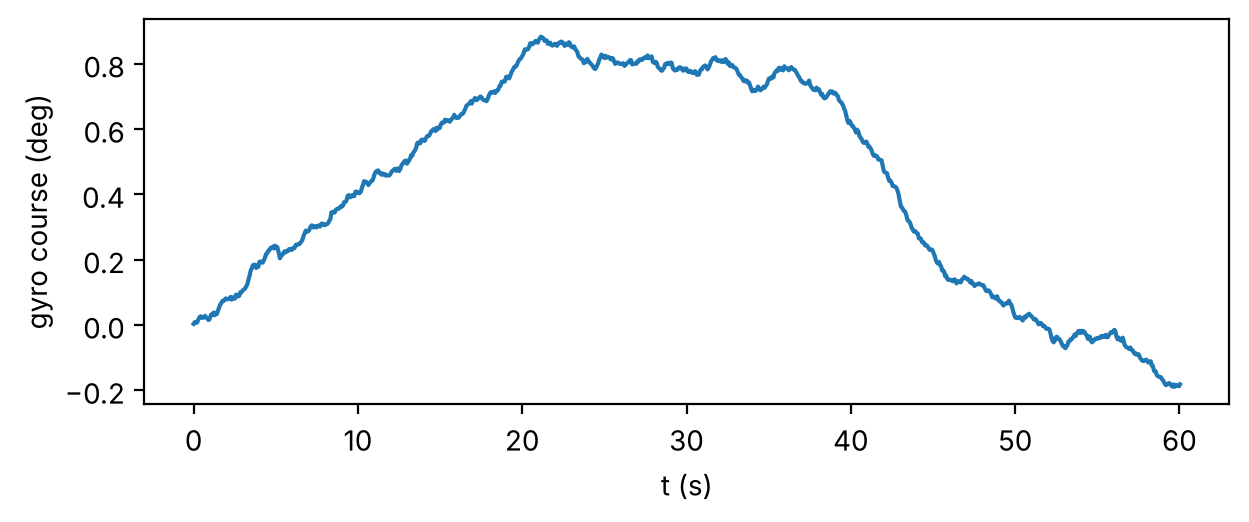

In [ ]:
e = estimate('cf_static.txt')
drift = np.degrees(e['gyro'][-1]) / e['t'][-1] * 60
print(f"gyro course after {e['t'][-1]:.0f} s = {np.degrees(e['gyro'][-1]):.2f}°  ->  drift = {drift:.2f} °/min  ->",
      'PASS' if abs(drift) < 1 else 'FAIL (limit 1 °/min)')
plt.figure(figsize=(7, 2.5)); plt.plot(e['t'], np.degrees(e['gyro'])); plt.xlabel('t (s)'); plt.ylabel('gyro course (deg)'); plt.show()

## 3. Runs: τ, check against the robot, reaction to the hand turn, course plots

cf_098.txt: K=0.98, measured dt = 62.7 ms, tau=3.074 s, recomputed vs logged course: max 0.007°
   hand turn seen by gyro +32.5°, encoders +25.0°, filtered course +31.8°  ->  heading error 5 s later changed by +1.2°
   robot held (wheels stopped) 7.1–8.7 s; course − course_odom = 5.4° after the turn, fell to 1/e of it after 0.51 s (tau = 3.074 s)
cf_050.txt: K=0.5, measured dt = 62.7 ms, tau=0.063 s, recomputed vs logged course: max 0.001°
   hand turn seen by gyro +32.7°, encoders +5.6°, filtered course +6.1°  ->  heading error 5 s later changed by +30.8°
   robot held (wheels stopped) 4.6–7.9 s; course − course_odom only 0.3° after the turn: course stays on course_odom (tau = 0.063 s)
cf_002.txt: K=0.02, measured dt = 62.7 ms, tau=0.001 s, recomputed vs logged course: max 0.000°
   hand turn seen by gyro +32.3°, encoders +4.8°, filtered course +4.8°  ->  heading error 5 s later changed by +33.0°
   robot held (wheels stopped) 4.5–8.1 s; course − course_odom only 0.0° after the turn: 

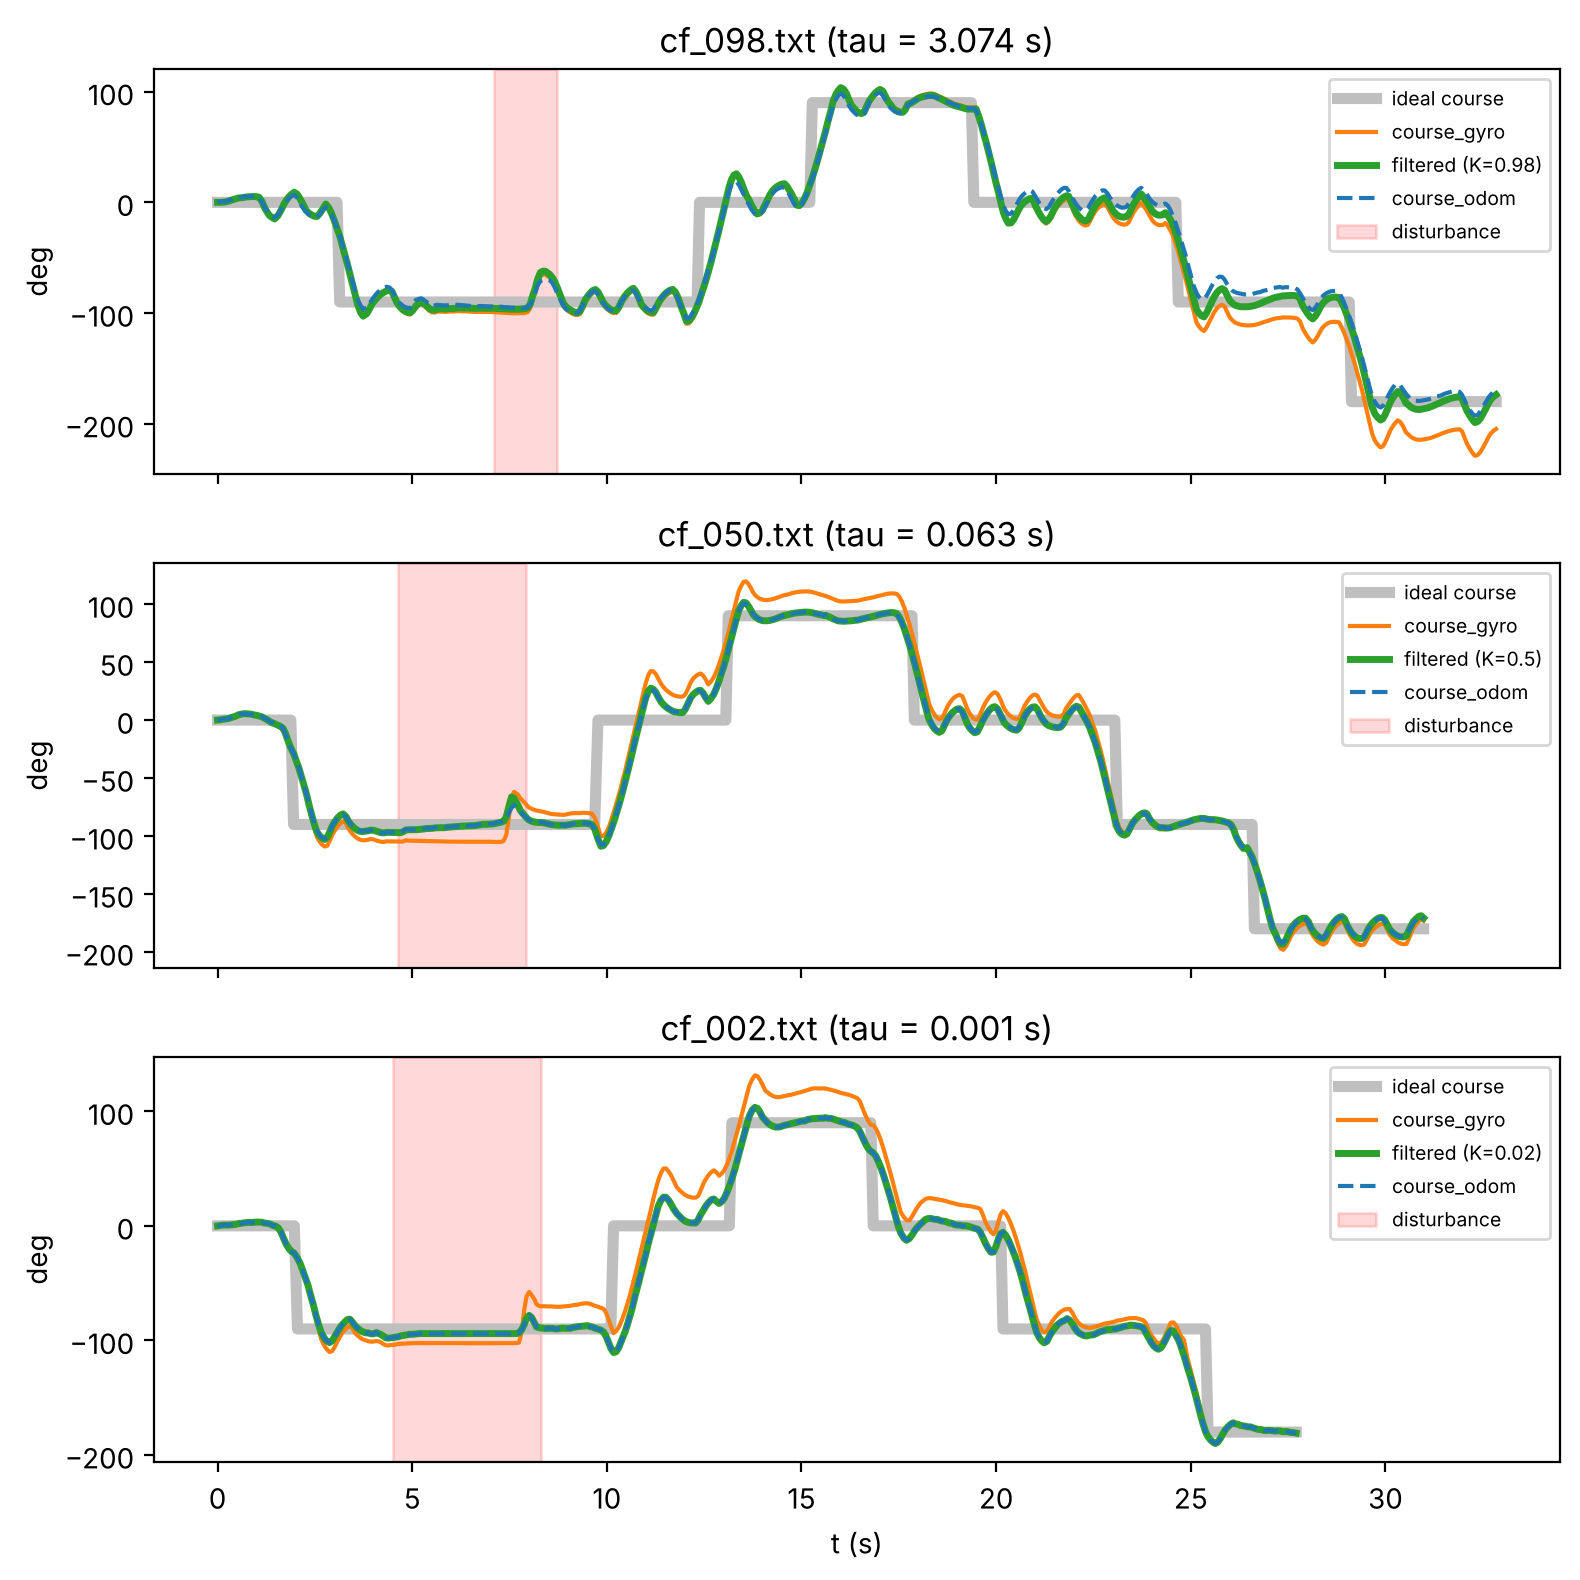

In [ ]:
R = {n: estimate(n) for n in RUNS}
fig, axs = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
for ax, (n, e) in zip(axs, R.items()):
    g, o, f = [np.degrees(e[k]) for k in ('gyro', 'odom', 'course')]
    a, b, c = np.searchsorted(e['t'], [HAND_TURN[n] - .5, HAND_TURN[n] + .4, HAND_TURN[n] + 5])
    w = (e['t'] > HAND_TURN[n] - 5) & (e['t'] < HAND_TURN[n] + 1)
    still = e['t'][1:][w[1:] & (np.diff(e['path']) < 1e-3)]   # wheels not moving
    t1, t2 = (still.min(), still.max()) if len(still) else (HAND_TURN[n], HAND_TURN[n])
    gap = np.abs(f - o); back = np.argmax(gap[b:] < gap[b] / np.e) if gap[b] > 1 else 0
    print(f"{n}: K={e['K']}, measured dt = {np.median(e['dt'])*1000:.1f} ms, tau={e['tau']:.3f} s, recomputed vs logged course: max {np.max(np.abs(f - np.degrees(e['logged']))):.3f}°\n"
          f"   hand turn seen by gyro {g[b]-g[a]:+.1f}°, encoders {o[b]-o[a]:+.1f}°, filtered course {f[b]-f[a]:+.1f}°"
          f"  ->  heading error 5 s later changed by {(g[c]-f[c]) - (g[a]-f[a]):+.1f}°\n"
          f"   robot held (wheels stopped) {t1:.1f}–{t2:.1f} s; " + (f"course − course_odom = {gap[b]:.1f}° after the turn, fell to 1/e of it after "
          f"{e['t'][b + back] - e['t'][b]:.2f} s (tau = {e['tau']:.3f} s)" if gap[b] > 1 else
          f"course − course_odom only {gap[b]:.1f}° after the turn: course stays on course_odom (tau = {e['tau']:.3f} s)"))
    ideal = f + np.degrees((C[segment(e)] - e['course'] + np.pi) % (2 * np.pi) - np.pi)   # ideal direction, same turn count as course
    ax.plot(e['t'], ideal, color='0.75', lw=4, label='ideal course')
    ax.plot(e['t'], g, color='C1', label='course_gyro'); ax.plot(e['t'], f, color='C2', lw=2.5, label=f"filtered (K={e['K']})")
    ax.plot(e['t'], o, color='C0', ls='--', label='course_odom')   # drawn last and dashed: visible even where it equals the filtered course
    ax.axvspan(t1, max(t2, HAND_TURN[n] + .4), color='r', alpha=.15, label='disturbance'); ax.set_title(f"{n} (tau = {e['tau']:.3f} s)"); ax.set_ylabel('deg'); ax.legend(fontsize=7)
axs[-1].set_xlabel('t (s)'); plt.tight_layout(); plt.show()

## 4. Trajectories and summary table

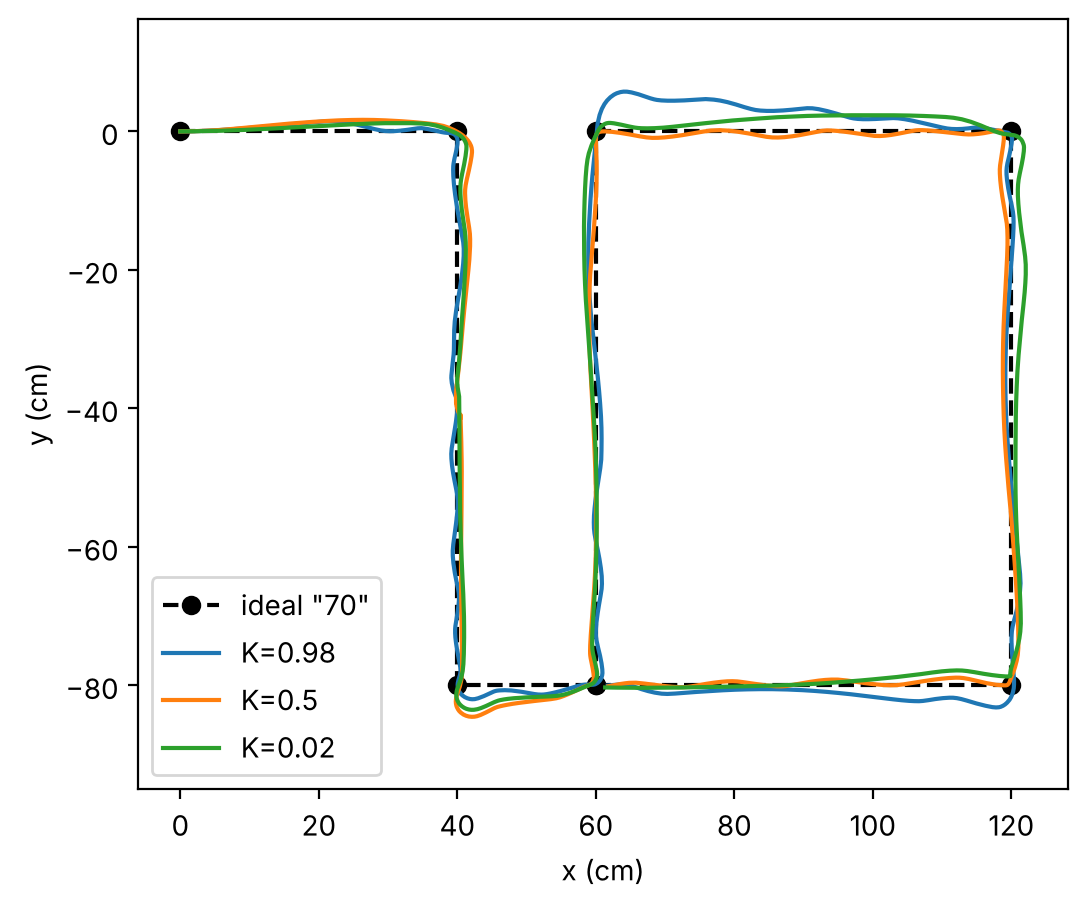

,Run,K,τ (s),max |distance| (cm),RMS distance (cm),mean |courseAngle| (°),final error (cm),behaviour after disturbance
0,cf_098.txt,0.98,3.0738,5.7,1.5,10.8,1.7,"noticed the turn, turned back, continued on course"
1,cf_050.txt,0.50,0.0627,4.5,1.1,10.8,1.8,"did not notice, drove on ~30° off course"
2,cf_002.txt,0.02,0.0013,3.5,1.1,12.2,1.4,"did not notice, drove on ~30° off course"


In [ ]:
rows = []; plt.figure(figsize=(6, 5)); plt.plot(X_ref, Y_ref, 'k--o', label='ideal "70"')
for n, e in R.items():
    dist, ca = [], []
    for p, c, i in zip(np.c_[e['x'], e['y']], e['course'], segment(e)):
        dist.append(-(p[0] - P[i, 0]) * np.sin(C[i]) + (p[1] - P[i, 1]) * np.cos(C[i]))
        ca.append((np.degrees(C[i] - c) + 180) % 360 - 180)
    dist = np.array(dist); plt.plot(e['x'], e['y'], label=f"K={e['K']}")
    rows.append({'Run': n, 'K': e['K'], 'τ (s)': round(e['tau'], 4), 'max |distance| (cm)': round(abs(dist).max(), 1),
                 'RMS distance (cm)': round(np.sqrt(np.mean(dist**2)), 1), 'mean |courseAngle| (°)': round(np.mean(np.abs(ca)), 1),
                 'final error (cm)': round(np.hypot(e['x'][-1] - X_ref[-1], e['y'][-1] - Y_ref[-1]), 1),
                 'behaviour after disturbance': BEHAVIOUR[n]})
plt.axis('equal'); plt.xlabel('x (cm)'); plt.ylabel('y (cm)'); plt.legend(); plt.show()
display(pd.DataFrame(rows))

## 5. What-if: other K recomputed offline
The raw sensor data does not depend on K, so the course can be recomputed for any K.
Run 1 (`cf_098`) is the run the lab asks for; there the robot turned itself back and the encoders missed only a few degrees of the hand turn.
Run 3 (`cf_002`) is added because there the encoders missed most of the turn, so the effect of K is easier to see.
Solid: measured. Dashed: ideal decay exp(−t/τ), started from the measured gap right after the turn.
"After 5 s" = mean of the measured gap over 1 s, 5 s after the turn ends (grey band).
The measured gap also picks up the gyro–encoder differences of the robot's own later turns (e.g. the spike at 13.3 s in run 1),
so with a long τ it can stay above the ideal curve, or even above the part of the turn the encoders missed.

cf_098.txt
   K=0.9: tau = 0.56 s -> of the 7.6° the encoders missed, 2.3° is still in the estimate after 5 s
   K=0.99: tau = 6.21 s -> of the 7.6° the encoders missed, 6.7° is still in the estimate after 5 s
   K=0.999: tau = 62.67 s -> of the 7.6° the encoders missed, 7.2° is still in the estimate after 5 s
cf_002.txt
   K=0.9: tau = 0.56 s -> of the 27.5° the encoders missed, 1.2° is still in the estimate after 5 s
   K=0.99: tau = 6.21 s -> of the 27.5° the encoders missed, 19.4° is still in the estimate after 5 s
   K=0.999: tau = 62.66 s -> of the 27.5° the encoders missed, 31.9° is still in the estimate after 5 s


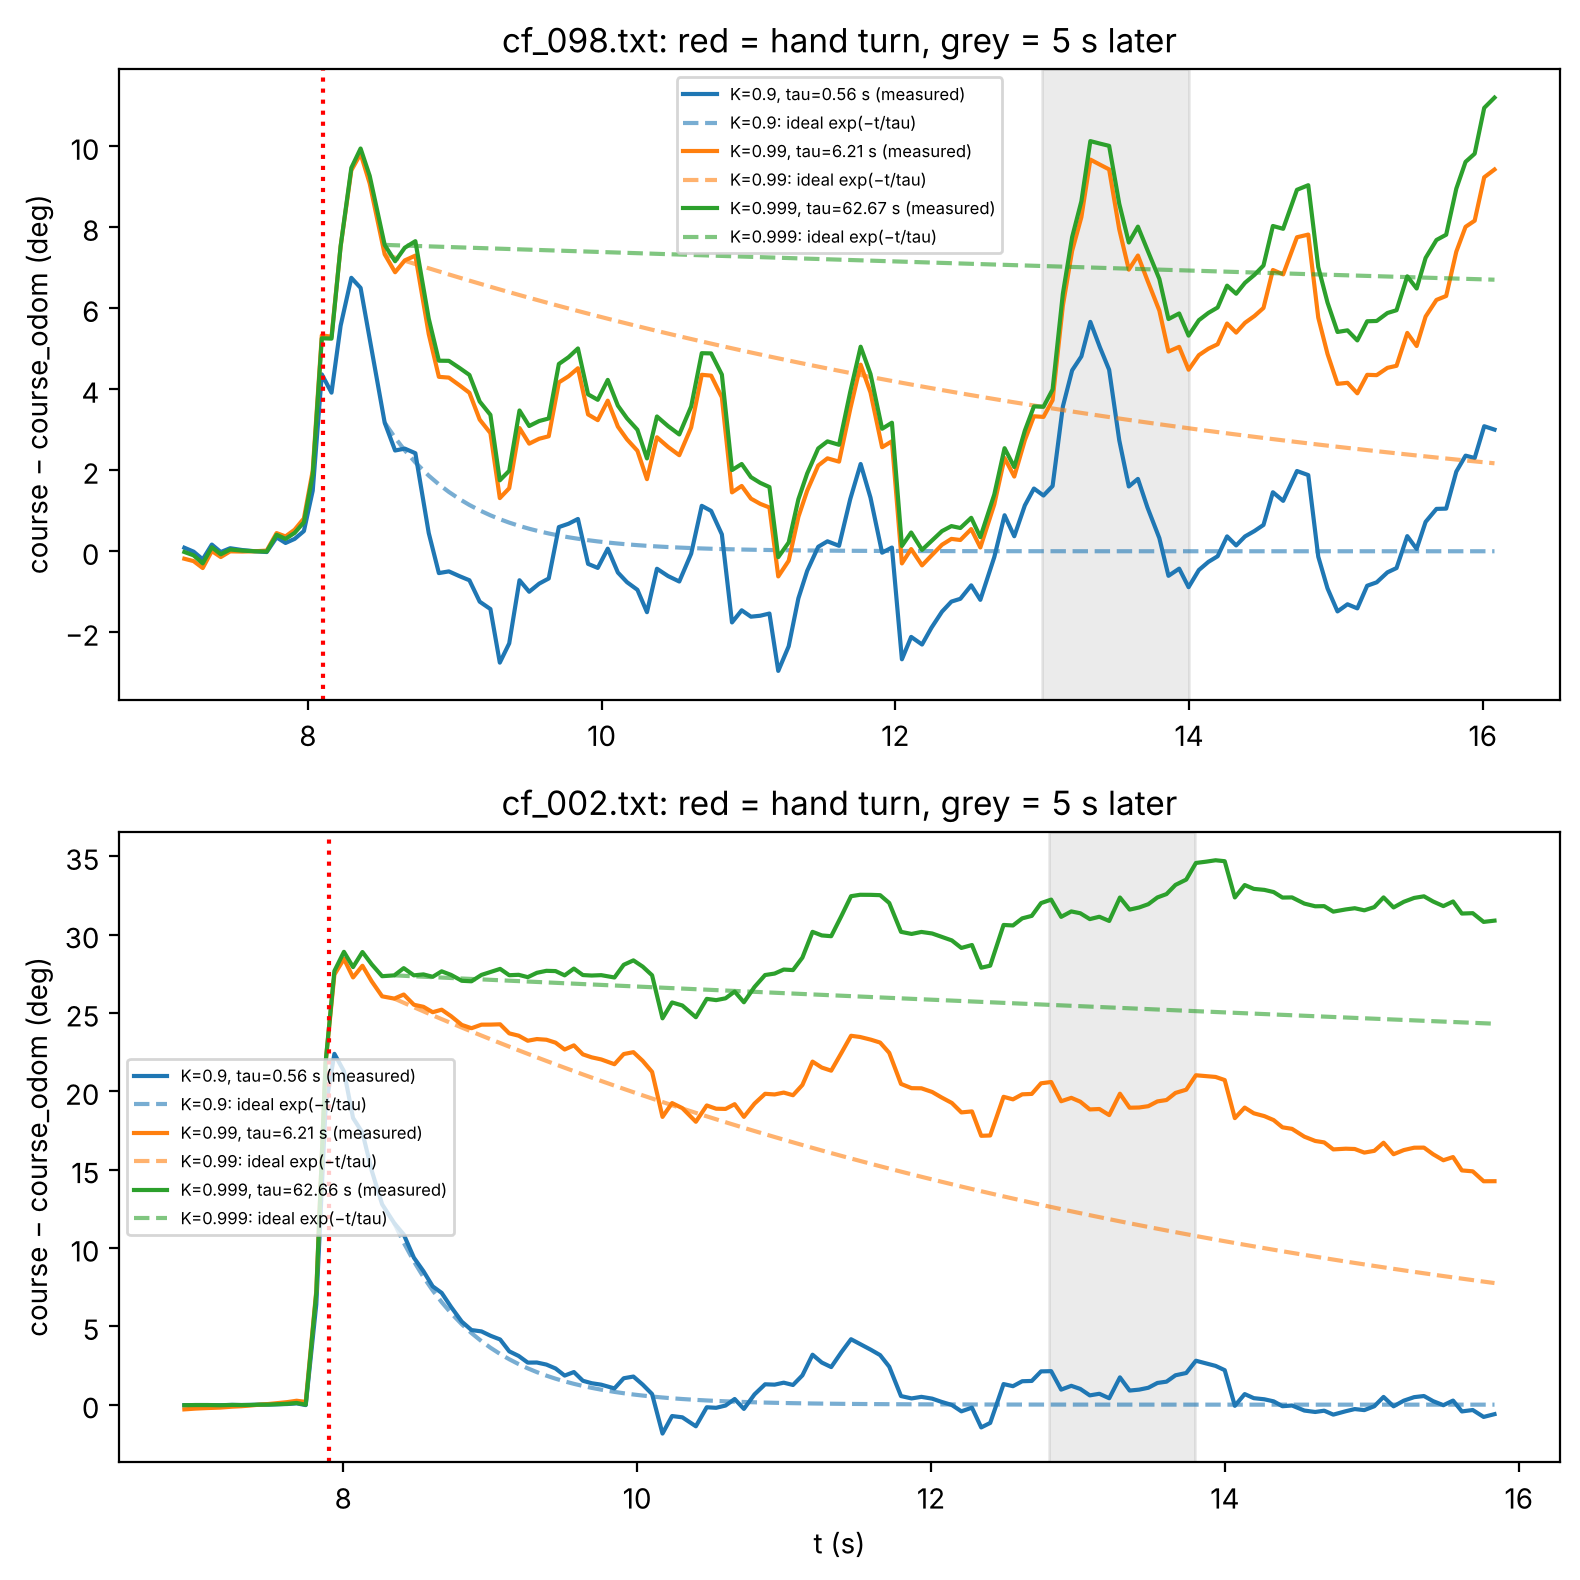

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(8, 8))
for ax, n in zip(axs, ['cf_098.txt', 'cf_002.txt']):
    t0 = HAND_TURN[n]; print(n)
    for K in [0.9, 0.99, 0.999]:
        e = estimate(n, K); a, b = np.searchsorted(e['t'], [t0 - .5, t0 + .4])
        gap = np.degrees(e['course'] - e['odom']); gap = gap - gap[a]           # change since just before the turn
        miss = np.degrees(e['gyro'] - e['odom']); miss = miss[b] - miss[a]    # part of the turn the encoders did not see
        held = gap[(e['t'] > t0 + 4.9) & (e['t'] < t0 + 5.9)].mean()
        print(f"   K={K}: tau = {e['tau']:.2f} s -> of the {miss:.1f}° the encoders missed, {held:.1f}° is still in the estimate after 5 s")
        w = (e['t'] > t0 - 1) & (e['t'] < t0 + 8); tt = e['t'][b:][e['t'][b:] < t0 + 8]
        l, = ax.plot(e['t'][w], gap[w], label=f"K={K}, tau={e['tau']:.2f} s (measured)")
        ax.plot(tt, gap[b] * np.exp(-(tt - tt[0]) / e['tau']), '--', color=l.get_color(), alpha=.6, label=f"K={K}: ideal exp(−t/tau)")
    ax.axvline(t0, color='r', ls=':'); ax.axvspan(t0 + 4.9, t0 + 5.9, color='k', alpha=.08)
    ax.set_title(f"{n}: red = hand turn, grey = 5 s later"); ax.set_ylabel('course − course_odom (deg)'); ax.legend(fontsize=6)
axs[-1].set_xlabel('t (s)'); plt.tight_layout(); plt.show()

## 6. Analysis
K = 0.98: retains enough gyroscope information to recognize the unexpected rotation and correct the robot's direction.
K = 0.50: forgets the gyroscope information too quickly.
K = 0.02: behaves almost entirely like odometry, defeating much of the purpose of introducing the gyroscope.


Larger K retains gyroscope information longer
When K increases, the complementary filter relies more on the gyro-based prediction and less on odometry. Therefore, the information about the manual rotation disappears more slowly.
2. Smaller K makes the filter return to odometry faster
For K = 0.9, the gap quickly approaches zero. This means the complementary filter gradually forgets the rotation that odometry failed to detect.
